# Local-Currency Risk & Hedging: COP vs MXN, BRL, CLP

A Colombian company with peso revenues should not carry dollar debt, so development banks lend more and more in local currency. The bank, though, funds itself in dollars, and every peso loan leaves it with a currency position it must either hedge or hold within a limit. This notebook measures how risky the peso is, compared with its neighbours, and finds the cheapest hedge that keeps the risk inside the limit.

**What it does.** It measures the risk of a Colombian peso (COP) exposure such as an MDB's local-currency loan book, compares it with the Mexican, Brazilian and Chilean currencies, forecasts its volatility, and designs the cheapest hedge that keeps the risk within limits.

**Data.** Daily USD exchange rates since 2018 (Yahoo Finance `COP=X`, `MXN=X`, `BRL=X`, `CLP=X`), local short-term interest rates (FRED / OECD), the U.S. 3-month T-bill and the VIX (FRED).

**Methods.** GARCH(1,1)-t per currency with a DCC model for time-varying correlations, and an out-of-sample volatility forecast comparison (GARCH, HAR and LightGBM).

Covered interest parity and carry price the hedge, and a `cvxpy` optimisation of direct and proxy hedges traces a cost–risk frontier.

**Key output.** The COP risk profile against its peers, dynamic correlations, next month's volatility forecast, the hedging cost curve and the optimal hedge mix, plus a local-currency risk dashboard.

## 1. Why local currency matters to an MDB

Development banks increasingly lend in **local currency**: a Colombian company with peso revenues should not carry dollar debt. The bank, however, funds itself in USD, so every peso loan creates a **long COP / short USD** position that it must either hedge or hold within a risk limit.

Three questions for the risk officer:

1. **How risky is COP**, on its own and next to MXN, BRL and CLP? Do these currencies move together, and does that change in a crisis?
2. **What volatility should the limits assume next month?** Forecasts drive VaR and the size of the open position the bank can hold.
3. **What does hedging cost, and which hedge is best?** A direct COP forward (NDF) is the cleanest hedge, but it costs the interest-rate differential plus a wider bid–offer than MXN. A **proxy hedge** in a cheaper, correlated currency leaves basis risk. The answer is a frontier, not a single number.

## 2. Key relationships

**Returns.** Quotes are local currency per USD, $S_t$. A long-COP position earns $r_t = -\Delta\ln S_t$ (positive when the peso appreciates).

**GARCH(1,1)-t:** $r_t = \mu + \sigma_t \varepsilon_t$, $\sigma_t^2 = \omega + \alpha r_{t-1}^2 + \beta \sigma_{t-1}^2$, with Student-t shocks for fat tails.

**DCC(1,1)** on the standardised residuals $z_t$:
$$Q_t = (1-a-b)\bar Q + a\, z_{t-1} z_{t-1}^\top + b\, Q_{t-1}, \qquad R_t = \operatorname{diag}(Q_t)^{-1/2} Q_t \operatorname{diag}(Q_t)^{-1/2}.$$

**Covered interest parity.** The forward that removes FX risk over $\tau$ years is $F = S\,\frac{1 + i_{loc}\tau}{1 + i_{USD}\tau}$. Selling COP forward therefore costs about $i_{COP} - i_{USD}$ a year: the bank gives up the peso's higher interest rate. Any cross-currency basis adds to that cost. It is not observable from free data, so we treat it as a sensitivity.

**Hedge optimisation.** With hedge notionals $h$ (fractions of the exposure sold forward in each currency), monthly return covariance $\Sigma$ and annual cost per unit $c$:
$$\min_h \;(e - h)^\top \Sigma\, (e - h) + \lambda\, c^\top |h|, \qquad e = \text{exposure vector (1 in COP)},$$
swept over $\lambda$ to trace the cost–risk frontier.

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import cvxpy as cp
import lightgbm as lgb
import statsmodels.api as sm
import yfinance as yf
from arch import arch_model
from scipy.optimize import minimize

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

CURRENCIES = {"COP": "COP=X", "MXN": "MXN=X", "BRL": "BRL=X", "CLP": "CLP=X"}
# Short-term (call money / interbank) rates, OECD Main Economic Indicators via
# FRED, monthly
LOCAL_RATES = {
    "COP": "COLIRSTCI01STM",
    "MXN": "IRSTCI01MXM156N",
    "BRL": "IRSTCI01BRM156N",
    "CLP": "IRSTCI01CLM156N",
}
# Yahoo's COP history before ~2018 has frequent bad prints (see section 4)
START = (
    "2018-01-01"
)
EXPOSURE_USD = 500_000_000  # COP loan book, USD equivalent
# out-of-sample period for forecasts and hedges
TEST_START = "2022-01-01"
HORIZON = 21  # one month, in business days
# Indicative bid–offer of a one-month forward or NDF, in bp of notional per
# roll (assumption, see section 10)
BID_OFFER_BP = {"COP": 8.0, "MXN": 2.0, "BRL": 6.0, "CLP": 5.0}
# hypothetical 1-month 99% VaR limit on the open COP position
VAR_LIMIT_USD = 25_000_000
SEED = 11

print(
    f"cvxpy {cp.__version__} · LightGBM {lgb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

cvxpy 1.9.3 · LightGBM 4.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


CCY_COLORS = {
    "COP": PALETTE[0],
    "MXN": PALETTE[1],
    "BRL": PALETTE[2],
    "CLP": PALETTE[3],
}

## 4. Data

- **FX:** daily closes from Yahoo Finance, quoted as local currency per USD. Yahoo's COP series before 2018 is unreliable: the price jumps 15–20% for a day and reverts, and weekly correlations with peers come out at zero. The sample therefore starts in 2018, and a filter repairs the remaining one-day bad prints.
- **Interest rates (FRED):** OECD short-term rates for Colombia, Mexico, Brazil and Chile (monthly, carried forward to daily) and the US 3-month T-bill `DTB3` (daily).
- **VIX (FRED `VIXCLS`):** global risk appetite, a feature for the volatility forecast.

In [3]:
def fetch_fx():
    px = yf.download(
        list(CURRENCIES.values()),
        start=START,
        progress=False,
        auto_adjust=False,
    )["Close"]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px = px.rename(columns={v: k for k, v in CURRENCIES.items()})[
        list(CURRENCIES)
    ]
    px.index.name, px.columns.name = "date", None
    return px.reset_index()


def fetch_macro():
    ids = list(LOCAL_RATES.values()) + ["DTB3", "VIXCLS"]
    return pd.concat(
        [
            pd.DataFrame({"date": s.index, "series": sid, "value": s.values})
            for sid in ids
            for s in [fred.get_series(sid, observation_start=START).dropna()]
        ],
        ignore_index=True,
    )


fx = cached("yahoo_latam_fx", fetch_fx).set_index("date").sort_index()
macro = (
    cached("fred_latam_rates_vix", fetch_macro)
    .pivot(index="date", columns="series", values="value")
    .sort_index()
)

# --- Cleaning: drop non-trading days and one-day bad prints that reverse the
# next day
fx = fx.dropna(how="all")
if fx.iloc[-1].isna().any():  # today's row is intraday and incomplete
    fx = fx.iloc[:-1]
fx = fx.ffill(limit=3)
raw = np.log(fx).diff()
scale = raw.abs().rolling(120, min_periods=40).median().shift() / 0.6745
spike = (raw.abs() > 10 * scale) & (
    (raw + raw.shift(-1)).abs() < 0.25 * raw.abs()
)
for c in fx.columns[spike.any()]:
    print(
        f"Data fix · {c}: bad print on"
        f" {', '.join(f'{d:%Y-%m-%d}' for d in spike.index[spike[c]])} interpolated"
    )
fx = fx.mask(spike).interpolate(limit_area="inside")
# long-local-currency return, decimal
rets = (-np.log(fx).diff()).dropna()
EVAL_DATE = rets.index.max()

# monthly series carried forward to daily
rates = macro.ffill().reindex(rets.index, method="ffill")
local = rates[list(LOCAL_RATES.values())].set_axis(list(LOCAL_RATES), axis=1)
usd = rates["DTB3"]
vix = rates["VIXCLS"]
print(
    f"{len(rets):,} days · {rets.index.min():%Y-%m-%d} →"
    f" {EVAL_DATE:%Y-%m-%d} · latest local rates: "
    + ", ".join(f"{c} {local[c].iloc[-1]:.2f}%" for c in local)
    + f" · USD 3M {usd.iloc[-1]:.2f}%"
)

2,288 days · 2018-01-02 → 2026-10-16 · latest local rates: COP 11.98%, MXN 5.20%, BRL 13.94%, CLP 4.50% · USD 3M 4.10%


## 5. COP against its peers

In [4]:
def max_drawdown(r):
    wealth = np.exp(r.cumsum())
    return (wealth / wealth.cummax() - 1).min()


profile = pd.DataFrame({
    "annual vol %": rets.std() * np.sqrt(252) * 100,
    "vol last year %": rets.iloc[-252:].std() * np.sqrt(252) * 100,
    "worst day %": rets.min() * 100,
    "worst month %": rets.rolling(HORIZON).sum().min() * 100,
    "max drawdown %": rets.apply(max_drawdown) * 100,
    "excess kurtosis": rets.kurt(),
    f"spot change since {fx.index[0]:%Y} %": (
        fx.iloc[-1] / fx.iloc[0] - 1
    ) * 100,
    "carry today (local − USD, %)": local.iloc[-1] - usd.iloc[-1],
})
corr_full = rets.corr()
print("Correlation of daily returns, full sample:")
print(corr_full.round(2).to_string())
profile.round(2)

Correlation of daily returns, full sample:
     COP  MXN  BRL  CLP
COP 1.00 0.32 0.27 0.39
MXN 0.32 1.00 0.41 0.29
BRL 0.27 0.41 1.00 0.29
CLP 0.39 0.29 0.29 1.00


,annual vol %,vol last year %,worst day %,worst month %,max drawdown %,excess kurtosis,spot change since 2018 %,"carry today (local − USD, %)"
COP,15.50,16.19,-7.21,-23.46,-47.49,3.30,8.16,7.88
MXN,12.06,8.64,-6.08,-28.74,-28.99,4.94,-6.15,1.10
BRL,15.68,12.16,-7.01,-15.87,-50.08,3.57,54.09,9.84
CLP,15.76,11.74,-4.28,-19.22,-44.67,12.58,59.92,0.40


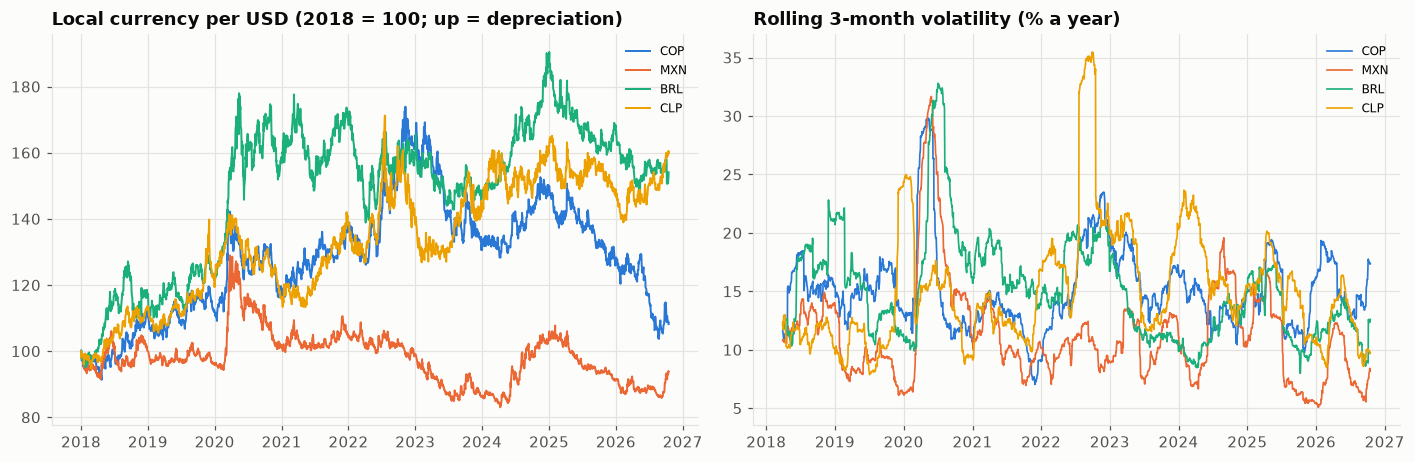

In [5]:
# --- Chart 1: LatAm FX and their volatility
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
for c in CURRENCIES:
    ax.plot(
        fx.index,
        fx[c] / fx[c].iloc[0] * 100,
        color=CCY_COLORS[c],
        lw=1.3,
        label=c,
    )
ax.set_title(
    f"Local currency per USD ({fx.index[0]:%Y} = 100; up = depreciation)"
)
ax.legend(fontsize=8)
ax = axes[1]
for c in CURRENCIES:
    ax.plot(
        rets.index,
        rets[c].rolling(63).std() * np.sqrt(252) * 100,
        color=CCY_COLORS[c],
        lw=1.1,
        label=c,
    )
ax.set_title("Rolling 3-month volatility (% a year)")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_fx_levels_and_vol")
plt.show()

## 6. Dynamic volatility and correlation: GARCH + DCC

A GARCH(1,1) with Student-t shocks per currency, fitted on the full sample (returns in %), then a DCC(1,1) estimated by maximum likelihood on the standardised residuals. Correlations that **rise in sell-offs** are what make a proxy hedge work in bad times. Correlations that **fall** are what make it fail.

In [6]:
garch_fits, std_resid, cond_vol = {}, {}, {}
for c in CURRENCIES:
    res = arch_model(
        rets[c] * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="t"
    ).fit(disp="off")
    garch_fits[c] = res
    std_resid[c] = res.std_resid
    # % a year
    cond_vol[c] = res.conditional_volatility * np.sqrt(252)
Z = pd.DataFrame(std_resid).dropna()
garch_table = pd.DataFrame({
    c: {
        "omega": r.params["omega"],
        "alpha": r.params["alpha[1]"],
        "beta": r.params["beta[1]"],
        "persistence α+β": r.params["alpha[1]"] + r.params["beta[1]"],
        "t dof ν": r.params["nu"],
    }
    for c, r in garch_fits.items()
}).T


def dcc_filter(params, z):
    a, b = params
    q_bar = np.cov(z.T)
    q = q_bar.copy()
    out, nll = np.empty((len(z), z.shape[1], z.shape[1])), 0.0
    for t in range(len(z)):
        if t > 0:
            q = (1 - a - b) * q_bar + a * np.outer(z[t - 1], z[t - 1]) + b * q
        d = 1 / np.sqrt(np.diag(q))
        r = q * np.outer(d, d)
        out[t] = r
        sign, logdet = np.linalg.slogdet(r)
        nll += 0.5 * (logdet + z[t] @ np.linalg.solve(r, z[t]) - z[t] @ z[t])
    return out, nll


z = Z.values
fit = minimize(
    lambda p: dcc_filter(p, z)[1],
    x0=[0.03, 0.95],
    method="SLSQP",
    bounds=[(1e-4, 0.3), (0.5, 0.999)],
    constraints=[{"type": "ineq", "fun": lambda p: 0.999 - p[0] - p[1]}],
)
DCC_A, DCC_B = fit.x
R_t, _ = dcc_filter(fit.x, z)
names = list(CURRENCIES)
dcc_corr = pd.DataFrame(
    {f"COP–{c}": R_t[:, 0, names.index(c)] for c in names[1:]}, index=Z.index
)
print(
    f"DCC: a = {DCC_A:.4f}, b = {DCC_B:.4f} (persistence {DCC_A + DCC_B:.3f})"
)
garch_table.round(3)

DCC: a = 0.0361, b = 0.8437 (persistence 0.880)


,omega,alpha,beta,persistence α+β,t dof ν
COP,0.24,0.20,0.55,0.76,6.34
MXN,0.03,0.16,0.80,0.96,5.78
BRL,0.01,0.03,0.96,0.99,5.92
CLP,0.03,0.09,0.88,0.97,6.26


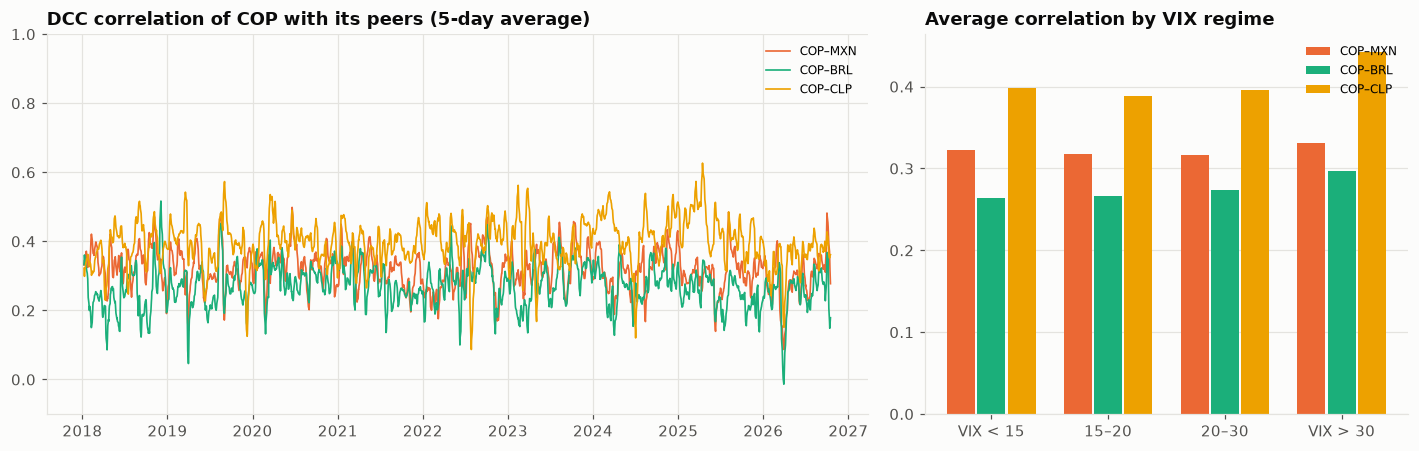

,COP–MXN,COP–BRL,COP–CLP
VIXCLS,,,
VIX < 15,0.32,0.26,0.40
15–20,0.32,0.27,0.39
20–30,0.32,0.27,0.40
VIX > 30,0.33,0.30,0.44


In [7]:
# Do correlations rise when global risk appetite falls? Average DCC correlation
# by VIX regime
regime = pd.cut(
    vix.reindex(dcc_corr.index),
    [0, 15, 20, 30, 100],
    labels=["VIX < 15", "15–20", "20–30", "VIX > 30"],
)
corr_by_regime = dcc_corr.groupby(regime, observed=True).mean()

fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.7, 1]}
)
ax = axes[0]
for col, c in zip(dcc_corr.columns, names[1:]):
    ax.plot(
        dcc_corr.index,
        dcc_corr[col].rolling(5).mean(),
        color=CCY_COLORS[c],
        lw=1.1,
        label=col,
    )
ax.set_title("DCC correlation of COP with its peers (5-day average)")
ax.set_ylim(-0.1, 1)
ax.legend(fontsize=8)
ax = axes[1]
xg = np.arange(len(corr_by_regime))
for k, (col, c) in enumerate(zip(dcc_corr.columns, names[1:])):
    ax.bar(
        xg + (k - 1) * 0.26,
        corr_by_regime[col],
        width=0.24,
        color=CCY_COLORS[c],
        label=col,
    )
ax.set_xticks(xg, corr_by_regime.index)
ax.set_title("Average correlation by VIX regime")
ax.legend(fontsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "02_dcc_correlations")
plt.show()
corr_by_regime.round(2)

## 7. Forecasting next month's COP volatility

The target is the **realised volatility of COP over the next 21 business days** (annualised), forecast every day. Three models, all trained up to 2021 and tested from 2022 onwards, with no look-ahead:

- **GARCH(1,1)-t:** parameters estimated on the training period, then run forward over the test period. Its 21-day-ahead variance is the sum of the daily forecasts.
- **HAR-RV** (Corsi, 2009): OLS of future volatility on past daily, weekly and monthly volatility.
- **LightGBM:** gradient-boosted trees on the HAR terms plus the peers' volatility, the VIX and recent absolute returns. Non-stationary levels such as the interest-rate carry are left out on purpose, because tree models cannot extrapolate beyond the range they were trained on.

They are scored with RMSE and **QLIKE**, a loss that penalises under-prediction of risk more than over-prediction, as a risk manager should.

In [8]:
r = rets["COP"]
# realised vol over the last w days, % a year
rv = lambda w: r.pow(2).rolling(w).mean().pow(0.5) * np.sqrt(252) * 100
target = (
    r.pow(2).rolling(HORIZON).mean().shift(-HORIZON) ** 0.5
    * np.sqrt(252)
    * 100
).rename("target")

feats = pd.DataFrame({
    "rv_1d": r.abs() * np.sqrt(252) * 100,
    "rv_5d": rv(5),
    "rv_21d": rv(21),
    "rv_63d": rv(63),
    "vix": vix,
    "abs_ret_5d": r.abs().rolling(5).sum() * 100,
})
# Note: the COP–USD carry is deliberately NOT a feature. Its level moved from
# ~2% (2018–21) to 5–8% (2022+), outside the training range, and trees cannot
# extrapolate: with it, LightGBM's test forecasts are badly biased.
for c in names[1:]:
    feats[f"rv_21d_{c}"] = (
        rets[c].pow(2).rolling(21).mean().pow(0.5) * np.sqrt(252) * 100
    )
data = pd.concat([feats, target], axis=1).dropna()
# gap avoids overlapping targets
train, test = data.loc[:TEST_START].iloc[:-HORIZON], data.loc[TEST_START:]

# HAR-RV
har_cols = ["rv_1d", "rv_5d", "rv_21d"]
har = sm.OLS(train["target"], sm.add_constant(train[har_cols])).fit()
pred_har = har.predict(sm.add_constant(test[har_cols]))

# LightGBM
gbm = lgb.LGBMRegressor(
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=40,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=SEED,
    verbose=-1,
)
gbm.fit(train.drop(columns="target"), train["target"])
pred_gbm = pd.Series(
    gbm.predict(test.drop(columns="target")), index=test.index
)

# GARCH: fit on training returns, then filter the full sample with those fixed
# parameters
g_train = arch_model(
    r.loc[:TEST_START] * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="t"
).fit(disp="off")
g_all = arch_model(
    r * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="t"
).fix(g_train.params)
fc = g_all.forecast(horizon=HORIZON, start=test.index[0], reindex=False)
pred_garch = (fc.variance.sum(axis=1) / HORIZON * 252) ** 0.5
pred_garch = pred_garch.reindex(test.index)

preds = pd.DataFrame(
    {"GARCH(1,1)-t": pred_garch, "HAR-RV": pred_har, "LightGBM": pred_gbm}
).dropna()
actual = test["target"].loc[preds.index]


def qlike(y, f):
    return np.mean(y**2 / f**2 - np.log(y**2 / f**2) - 1)


scores = pd.DataFrame({
    m: {
        "RMSE (vol pts)": np.sqrt(np.mean((actual - p) ** 2)),
        "QLIKE": qlike(actual, p),
        "bias (vol pts)": (p - actual).mean(),
        "hit: |error| < 3 pts %": (np.abs(p - actual) < 3).mean() * 100,
    }
    for m, p in preds.items()
}).T
importance = pd.Series(
    gbm.feature_importances_, index=train.drop(columns="target").columns
).sort_values(ascending=False)
print("LightGBM most used features: " + ", ".join(importance.index[:5]))
scores.round(3)

LightGBM most used features: rv_21d, rv_21d_BRL, rv_63d, vix, rv_21d_CLP


,RMSE (vol pts),QLIKE,bias (vol pts),hit: |error| < 3 pts %
"GARCH(1,1)-t",4.05,0.14,0.20,50.57
HAR-RV,4.06,0.15,-0.50,51.80
LightGBM,5.62,0.38,-0.85,40.85


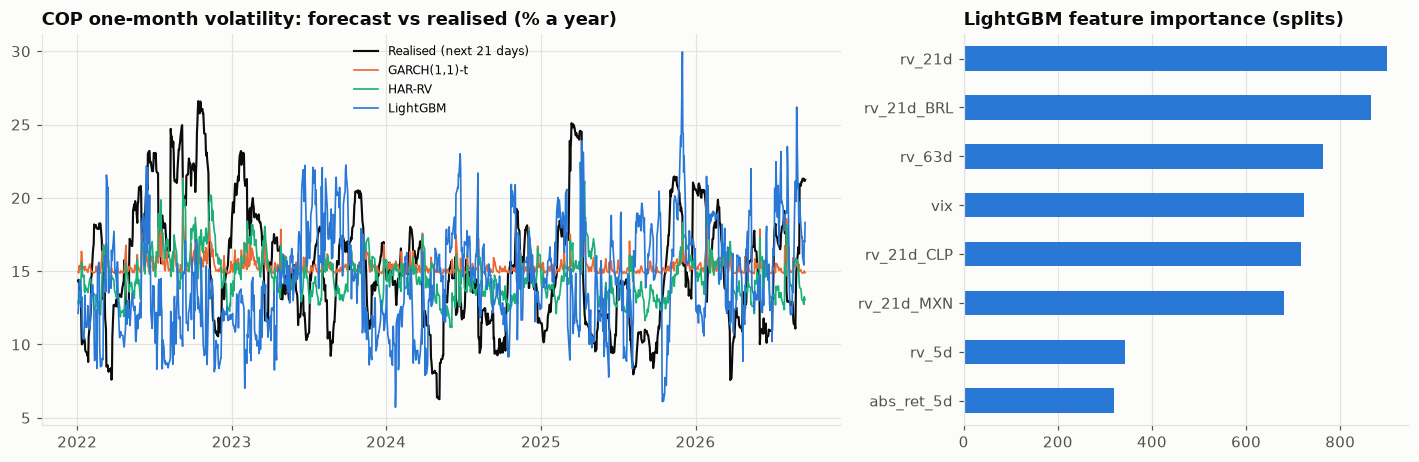

Best model by QLIKE: GARCH(1,1)-t · COP volatility forecast for the next month: GARCH(1,1)-t 15.0%, HAR-RV 15.0%, LightGBM 14.2%


In [9]:
# --- Chart 3: forecasts vs realised volatility in the test period
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.8, 1]}
)
ax = axes[0]
ax.plot(
    actual.index, actual, color=INK, lw=1.4, label="Realised (next 21 days)"
)
for (m, p), color in zip(preds.items(), [PALETTE[1], PALETTE[2], PALETTE[0]]):
    ax.plot(p.index, p, color=color, lw=1.1, label=m)
ax.set_title("COP one-month volatility: forecast vs realised (% a year)")
ax.legend(fontsize=8)
ax = axes[1]
importance.head(8)[::-1].plot.barh(ax=ax, color=PALETTE[0])
ax.set_title("LightGBM feature importance (splits)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "03_vol_forecasts")
plt.show()

best_model = scores["QLIKE"].idxmin()
# Forecast for the month starting today: refit-free one-step from the latest
# features / GARCH state
latest_feats = feats.dropna().iloc[[-1]]
vol_now = {
    "GARCH(1,1)-t": float(
        (
            g_all.forecast(horizon=HORIZON, start=r.index[-1], reindex=False)
            .variance.iloc[-1]
            .sum()
            / HORIZON
            * 252
        )
        ** 0.5
    ),
    "HAR-RV": float(
        har.predict(
            sm.add_constant(latest_feats[har_cols], has_constant="add")
        ).iloc[0]
    ),
    "LightGBM": float(gbm.predict(latest_feats)[0]),
}
VOL_FORECAST = vol_now[best_model]
print(
    f"Best model by QLIKE: {best_model} · COP volatility forecast for the next"
    " month: "
    + ", ".join(f"{m} {v:.1f}%" for m, v in vol_now.items())
)

## 8. What does hedging cost? Carry and covered interest parity

Selling COP forward locks in today's rate adjusted by the interest differential. For a bank that is long pesos the cost is the **carry it gives up**, $i_{COP} - i_{USD}$, plus the bid–offer of rolling a forward every month. The chart shows that hedging COP has cost between about 3% and 9% a year since 2018.

That is the price of certainty, and the reason some MDBs keep part of the position open within a VaR limit.

In [10]:
carry = local.sub(usd, axis=0)  # % a year
# + rolling bid–offer, % a year
hedge_cost = carry.add(pd.Series(BID_OFFER_BP) * 12 / 100, axis=1)
cip = pd.DataFrame({
    "spot": fx.iloc[-1],
    "local rate %": local.iloc[-1],
    "USD rate %": usd.iloc[-1],
})
for tau, lab in [(1 / 12, "1M"), (0.25, "3M"), (1.0, "12M")]:
    cip[f"CIP forward {lab}"] = (
        cip["spot"]
        * (1 + cip["local rate %"] / 100 * tau)
        / (1 + cip["USD rate %"] / 100 * tau)
    )
cip["annual hedge cost %"] = hedge_cost.iloc[-1]
cip["hedge cost per year on USD 500mm ($mm)"] = (
    cip["annual hedge cost %"] / 100 * EXPOSURE_USD / 1e6
)

# Was the carry worth it? Unhedged long-local returns = spot return + carry,
# annualised by year
unhedged = rets.add(carry / 100 / 252, axis=0)
yearly = pd.DataFrame({
    "spot only %": rets.groupby(rets.index.year).sum()["COP"] * 100,
    "carry %": (carry["COP"] / 252).groupby(carry.index.year).sum(),
    "unhedged total %": (
        unhedged["COP"].groupby(unhedged.index.year).sum() * 100
    ),
})
print("COP: spot vs carry by year (% of exposure)")
print(yearly.round(1).T.to_string())
cip.round(3)

COP: spot vs carry by year (% of exposure)
date               2018  2019  2020   2021   2022  2023   2024  2025  2026
spot only %      -10.00 -1.20 -4.10 -17.30 -17.50 22.30 -12.70 16.30 16.40
carry %            2.50  2.30  2.60   2.00   5.40  8.20   6.70  5.40  6.10
unhedged total %  -7.50  1.10 -1.50 -15.40 -12.20 30.50  -6.00 21.70 22.40


,spot,local rate %,USD rate %,CIP forward 1M,CIP forward 3M,CIP forward 12M,annual hedge cost %,hedge cost per year on USD 500mm ($mm)
COP,"3,175.59",11.98,4.10,"3,196.37","3,237.51","3,415.97",8.84,44.20
MXN,18.44,5.20,4.10,18.46,18.49,18.64,1.34,6.70
BRL,5.10,13.94,4.10,5.14,5.22,5.58,10.56,52.80
CLP,981.09,4.50,4.10,981.42,982.06,984.86,1.00,5.00


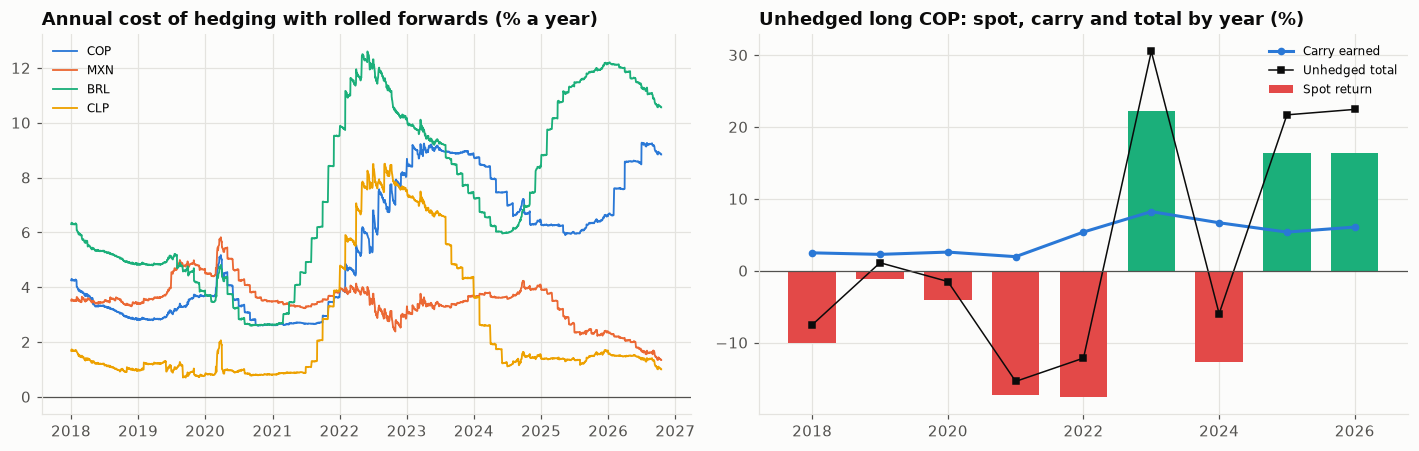

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
for c in CURRENCIES:
    ax.plot(
        hedge_cost.index, hedge_cost[c], color=CCY_COLORS[c], lw=1.2, label=c
    )
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_title("Annual cost of hedging with rolled forwards (% a year)")
ax.legend(fontsize=8)
ax = axes[1]
xy = yearly.index.astype(int)
ax.bar(
    xy,
    yearly["spot only %"],
    color=[
        STATUS["green"] if v > 0 else STATUS["red"]
        for v in yearly["spot only %"]
    ],
    width=0.7,
    label="Spot return",
)
ax.plot(
    xy,
    yearly["carry %"],
    color=PALETTE[0],
    marker="o",
    ms=4,
    label="Carry earned",
)
ax.plot(
    xy,
    yearly["unhedged total %"],
    color=INK,
    marker="s",
    ms=4,
    lw=1,
    label="Unhedged total",
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_title("Unhedged long COP: spot, carry and total by year (%)")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "04_hedge_cost_and_carry")
plt.show()

## 9. Designing the hedge: direct NDF vs proxy currencies

The position: USD 500 mm of COP loans. The bank can sell forward any mix of COP, MXN, BRL and CLP. MXN is the most liquid emerging-market currency and correlated with COP, so it is the classic proxy.

We estimate the covariance of monthly (21-day) returns on 2018–2021 and solve the cost-penalised minimum-variance problem for a range of penalties $\lambda$. This traces the **frontier** from "no hedge" (cheapest, riskiest) to "full direct hedge". Each hedge is then evaluated **out of sample** from 2022 on, which is the real test of a proxy hedge.

In [12]:
# non-overlapping monthly returns
monthly = rets.rolling(HORIZON).sum().iloc[::HORIZON].dropna()
est, oos = monthly.loc[:"2021"], monthly.loc[TEST_START:]
SIGMA_M = est.cov().values
# annual cost per unit hedged
cost_now = hedge_cost.iloc[-1].values / 100
# exposure: long COP
e = np.array([1.0, 0, 0, 0])


def solve_hedge(lam, allowed=None):
    h = cp.Variable(4)
    cons = [h >= 0, h <= 1.0]
    if allowed is not None:
        cons += [h[i] == 0 for i in range(4) if names[i] not in allowed]
    cp.Problem(
        cp.Minimize(cp.quad_form(e - h, SIGMA_M) * 12 + lam * cost_now @ h),
        cons,
    ).solve()
    return np.clip(h.value, 0, None)


def evaluate(h, sample):
    # monthly hedged return per unit exposure
    pnl = sample.values @ (e - h)
    var99 = -np.quantile(pnl, 0.01)
    return {
        "vol % a year": pnl.std() * np.sqrt(12) * 100,
        "1M VaR99 ($mm)": var99 * EXPOSURE_USD / 1e6,
        "cost % a year": cost_now @ h * 100,
        "cost $mm a year": cost_now @ h * EXPOSURE_USD / 1e6,
    }


frontier = []
for lam in np.r_[0, np.geomspace(0.002, 2, 30)]:
    for label, allowed in [
        ("All four", None),
        ("Proxies only (no COP)", ["MXN", "BRL", "CLP"]),
    ]:
        h = solve_hedge(lam, allowed)
        frontier.append({
            "set": label,
            "lambda": lam,
            **dict(zip(names, h)),
            **evaluate(h, oos),
        })
frontier = pd.DataFrame(frontier)

named = {
    "Unhedged": np.zeros(4),
    "Full COP NDF": np.array([1.0, 0, 0, 0]),
    "Half COP NDF": np.array([0.5, 0, 0, 0]),
    "MXN proxy (min-var ratio)": solve_hedge(0, ["MXN"]),
    "Proxy basket (min-var)": solve_hedge(0, ["MXN", "BRL", "CLP"]),
}
strategies = pd.DataFrame({
    k: {**dict(zip(names, np.round(v, 2))), **evaluate(v, oos)}
    for k, v in named.items()
}).T
strategies["out-of-sample effectiveness %"] = (
    1
    - (strategies["vol % a year"] / strategies.loc["Unhedged", "vol % a year"])
    ** 2
) * 100
strategies.round(2)

,COP,MXN,BRL,CLP,vol % a year,1M VaR99 ($mm),cost % a year,cost $mm a year,out-of-sample effectiveness %
Unhedged,0.00,0.00,0.00,0.00,15.01,56.83,0.00,0.00,0.00
Full COP NDF,1.00,0.00,0.00,0.00,0.00,-0.00,8.84,44.20,100.00
Half COP NDF,0.50,0.00,0.00,0.00,7.51,28.41,4.42,22.10,75.00
MXN proxy (min-var ratio),0.00,0.56,0.00,0.00,13.23,52.54,0.76,3.78,22.33
Proxy basket (min-var),0.00,0.47,0.11,0.11,12.26,44.95,1.89,9.45,33.36


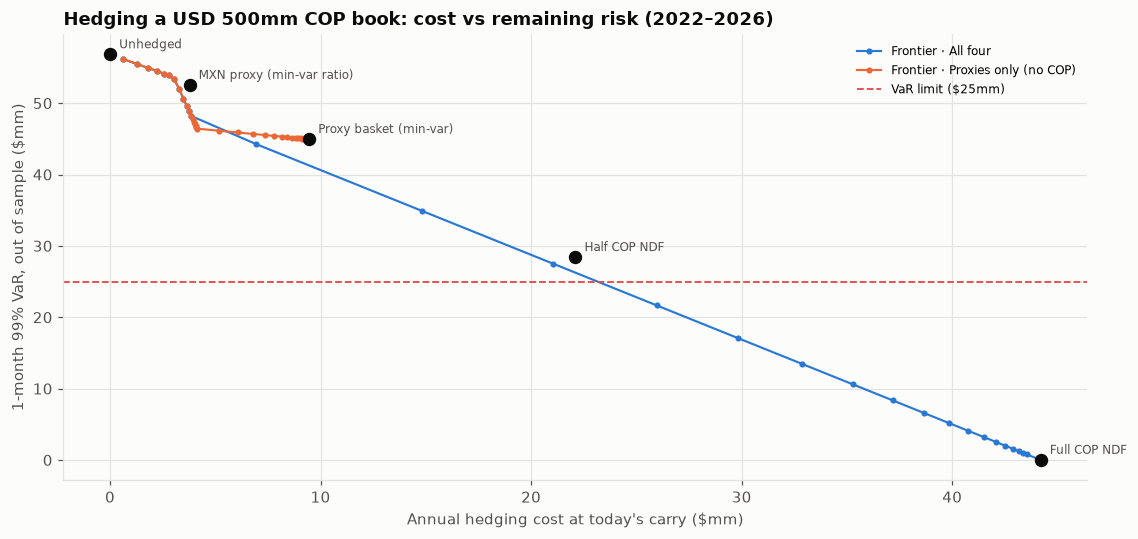

Cheapest hedge within the VaR limit: COP 55%, MXN 22%, BRL 0%, CLP 5% · cost $26.0mm a year · VaR $21.7mm


In [13]:
# --- Chart 5: the cost–risk frontier, out of sample
fig, ax = plt.subplots(figsize=(10.5, 5))
for label, color in [
    ("All four", PALETTE[0]),
    ("Proxies only (no COP)", PALETTE[1]),
]:
    f = frontier[frontier["set"] == label].sort_values("cost % a year")
    ax.plot(
        f["cost $mm a year"],
        f["1M VaR99 ($mm)"],
        color=color,
        marker="o",
        ms=3,
        lw=1.4,
        label=f"Frontier · {label}",
    )
for name, row in strategies.iterrows():
    ax.scatter(
        row["cost $mm a year"],
        row["1M VaR99 ($mm)"],
        s=60,
        color=INK,
        zorder=3,
    )
    ax.annotate(
        name,
        (row["cost $mm a year"], row["1M VaR99 ($mm)"]),
        xytext=(6, 4),
        textcoords="offset points",
        fontsize=8,
        color=INK_2,
    )
ax.axhline(
    VAR_LIMIT_USD / 1e6,
    color=STATUS["red"],
    ls="--",
    lw=1.2,
    label=f"VaR limit (${VAR_LIMIT_USD/1e6:.0f}mm)",
)
ax.set_xlabel("Annual hedging cost at today's carry ($mm)")
ax.set_ylabel("1-month 99% VaR, out of sample ($mm)")
ax.set_title(
    "Hedging a USD 500mm COP book: cost vs remaining risk (2022–2026)"
)
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "05_hedge_frontier")
plt.show()

# Cheapest hedge on the 'all four' frontier that respects the VaR limit
ok = frontier[
    (frontier["set"] == "All four")
    & (frontier["1M VaR99 ($mm)"] <= VAR_LIMIT_USD / 1e6)
]
CHEAPEST = (
    ok.sort_values("cost $mm a year").iloc[0]
    if len(ok)
    else frontier.sort_values("1M VaR99 ($mm)").iloc[0]
)
print(
    "Cheapest hedge within the VaR limit: "
    + ", ".join(f"{c} {CHEAPEST[c]:.0%}" for c in names)
    + f" · cost ${CHEAPEST['cost $mm a year']:.1f}mm a year · VaR"
    f" ${CHEAPEST['1M VaR99 ($mm)']:.1f}mm"
)

## 10. Local-currency risk dashboard

In [14]:
# parametric, forecast vol
open_var = (
    VOL_FORECAST / 100 * np.sqrt(HORIZON / 252) * 2.33 * EXPOSURE_USD / 1e6
)
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.15,
    horizontal_spacing=0.1,
    specs=[[{}, {}], [{}, {"type": "table"}]],
    subplot_titles=(
        "Rolling 3-month volatility (% a year)",
        "DCC correlation of COP with peers",
        "Cost vs out-of-sample VaR of hedges ($mm)",
        "Scorecard",
    ),
)
for c in CURRENCIES:
    dash.add_trace(
        go.Scatter(
            x=rets.index[-1500:],
            y=(rets[c].rolling(63).std() * np.sqrt(252) * 100).iloc[-1500:],
            name=c,
            line=dict(color=CCY_COLORS[c], width=1.3),
            legendgroup=c,
        ),
        1,
        1,
    )
for col, c in zip(dcc_corr.columns, names[1:]):
    dash.add_trace(
        go.Scatter(
            x=dcc_corr.index[-1500:],
            y=dcc_corr[col].rolling(5).mean().iloc[-1500:],
            name=col,
            line=dict(color=CCY_COLORS[c], width=1.2, dash="dot"),
            showlegend=True,
        ),
        1,
        2,
    )
for label, color in [
    ("All four", PALETTE[0]),
    ("Proxies only (no COP)", PALETTE[1]),
]:
    f = frontier[frontier["set"] == label].sort_values("cost % a year")
    dash.add_trace(
        go.Scatter(
            x=f["cost $mm a year"],
            y=f["1M VaR99 ($mm)"],
            mode="lines+markers",
            name=f"Frontier · {label}",
            line=dict(color=color),
            marker=dict(size=4),
        ),
        2,
        1,
    )
dash.add_hline(
    y=VAR_LIMIT_USD / 1e6,
    line=dict(color=STATUS["red"], dash="dash"),
    row=2,
    col=1,
)
rows = [
    ("COP vol, last year", f"{profile.loc['COP', 'vol last year %']:.1f}%"),
    (f"Next-month vol forecast ({best_model})", f"{VOL_FORECAST:.1f}%"),
    (
        "1M VaR99 if unhedged (forecast)",
        f"${open_var:,.1f}mm vs limit ${VAR_LIMIT_USD/1e6:.0f}mm "
        + ("🔴" if open_var > VAR_LIMIT_USD / 1e6 else "🟢"),
    ),
    (
        "Carry given up by hedging COP",
        f"{hedge_cost['COP'].iloc[-1]:.2f}% a year",
    ),
    (
        "Cheapest hedge within limit",
        ", ".join(
            f"{c} {CHEAPEST[c]:.0%}" for c in names if CHEAPEST[c] > 0.005
        )
        or "none",
    ),
    ("Its annual cost", f"${CHEAPEST['cost $mm a year']:.1f}mm"),
    (
        "MXN proxy effectiveness (OOS)",
        (
            f"{strategies.loc['MXN proxy (min-var ratio)', 'out-of-sample effectiveness %']:.0f}%"
        ),
    ),
]
dash.add_trace(
    go.Table(
        header=dict(
            values=["Metric", "Value"],
            fill_color="#f1f0ec",
            font=dict(color=INK, size=12),
            align="left",
        ),
        cells=dict(
            values=list(zip(*rows)),
            fill_color=SURFACE,
            font=dict(color=INK_2, size=12),
            align="left",
            height=28,
        ),
    ),
    2,
    2,
)
dash.update_layout(
    height=900,
    width=1350,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=-0.07),
    margin=dict(t=110),
    title=dict(
        x=0.01,
        text=(
            "<b>Local-currency risk · USD 500mm COP book ·"
            f" {EVAL_DATE:%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>COP"
            f" {fx['COP'].iloc[-1]:,.0f} per USD · forecast vol"
            f" {VOL_FORECAST:.1f}% · hedge cost"
            f" {hedge_cost['COP'].iloc[-1]:.1f}% a year · cheapest compliant"
            f" hedge ${CHEAPEST['cost $mm a year']:.1f}mm a year</span>"
        ),
    ),
)
dash.update_xaxes(title_text="annual cost ($mm)", row=2, col=1)
save_dashboard(dash, "dashboard")

profile.to_csv(OUT_DIR / "currency_risk_profile.csv")
scores.to_csv(OUT_DIR / "vol_forecast_scores.csv")
strategies.to_csv(OUT_DIR / "hedge_strategies_oos.csv")
frontier.to_csv(OUT_DIR / "hedge_frontier.csv", index=False)
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 11. Reading the results and limitations

**What to take away**

- **COP is a 15–16% volatility currency**, comparable to BRL and CLP and clearly riskier than MXN. Its worst month cost almost a quarter of the exposure.
- **Correlations with the peers are modest and stable.** Daily correlations of 0.3–0.4 barely change with the VIX regime and rise only slightly above VIX 30. Proxy hedges therefore do not collapse in stress, but they never remove much risk either.

**Simple models forecast volatility best.** GARCH and HAR tie on QLIKE and RMSE out of sample. COP's GARCH persistence is low (α + β ≈ 0.76), so its one-month forecast stays close to the long-run level: in this currency, shocks fade within weeks. The tree model does not beat them: with only a few years of reliable data, structure beats flexibility. The GARCH forecast feeds the open-position VaR in the dashboard.

- **Hedging is expensive and the cost is the carry.** At today's rates, selling COP forward costs about 9% a year, roughly USD 44 mm on a USD 500 mm book. The unhedged position earned 2–8% a year of carry since 2018 but lost more than that in 2021–2022, which is exactly the trade-off the VaR limit arbitrates.
- **Proxies are cheap but leaky.** Out of sample, an MXN hedge removes only about a fifth of the variance and the best proxy basket about a third. The cheapest hedge that respects the VaR limit is still mostly COP (about 55%), topped up with MXN and CLP, at roughly 60% of the cost of a full NDF hedge.

**Limitations**

- **Cross-currency basis and NDF onshore/offshore spreads** are not available from free data. Real hedge costs differ from the CIP estimate by the basis, typically tens of basis points.
- **Bid–offer assumptions** are indicative, not market quotes.
- **Monthly OECD rates** are carried forward to daily, so short-term carry jumps are smoothed.
- **Stationarity.** The hedge covariance comes from 2018–2021; correlations shift (section 6), so hedge ratios must be re-estimated regularly.

## References

### Finance and regulation

- Engle, R. (2002). Dynamic conditional correlation: A simple class of multivariate generalized autoregressive conditional heteroskedasticity models. *Journal of Business & Economic Statistics, 20*(3), 339–350. https://doi.org/10.1198/073500102288618487
- Corsi, F. (2009). A simple approximate long-memory model of realized volatility. *Journal of Financial Econometrics, 7*(2), 174–196. https://doi.org/10.1093/jjfinec/nbp001
- Du, W., Tepper, A., & Verdelhan, A. (2018). Deviations from covered interest rate parity. *The Journal of Finance, 73*(3), 915–957. https://doi.org/10.1111/jofi.12620
- Lustig, H., & Verdelhan, A. (2007). The cross section of foreign currency risk premia and consumption growth risk. *American Economic Review, 97*(1), 89–117. https://doi.org/10.1257/aer.97.1.89
- Eichengreen, B., Hausmann, R., & Panizza, U. (2007). Currency mismatches, debt intolerance, and the original sin: Why they are not the same and why it matters. In S. Edwards (Ed.), *Capital controls and capital flows in emerging economies* (pp. 121–170). University of Chicago Press. https://doi.org/10.7208/chicago/9780226184999.003.0004

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Diamond, S., & Boyd, S. (2016). CVXPY: A Python-embedded modeling language for convex optimization. *Journal of Machine Learning Research, 17*(83), 1–5. https://jmlr.org/papers/v17/15-408.html